# NHANES — Giai đoạn 3 · Bước 7: Model Explainability

**Người chạy:** Bạn trên Jupyter Notebook, **không phải ChatGPT**. Notebook này **chưa chạy** và **không huấn luyện** mô hình.

**Quan trọng:** Bước 6B đã đọc Test holdout một lần. Chúng ta không được dùng Test để thử lựa chọn feature, sửa ngưỡng hoặc đánh giá lại. Notebook này **chỉ** dùng `validation.csv` từ Bước 5 và model đã đóng.

**Bài toán gốc:** phân loại chỉ dấu HbA1c ≥5,7% ở cohort nghiên cứu NHANES; **không** chẩn đoán hoặc dự đoán type 2 tương lai.

**Bạn cần có:** `models/baseline/nhanes_hba1c_baseline_step5.joblib`, `data/outputs/model_training/validation.csv`, `data/outputs/model_training/step5_metadata.json`.


## 0. Kiểm tra môi trường

Chọn cùng kernel của Bước 5–6 (Python 3.13.9, scikit-learn 1.8.0 theo kết quả bạn cung cấp). Nếu thiếu thư viện: `%pip install scikit-learn pandas matplotlib joblib scipy`. **Không cần cài SHAP cho baseline này**: trước tiên dùng coefficients + permutation importance + phân rã logit; cân nhắc SHAP sau khi hiểu cách giải thích tuyến tính.

> **Cảnh báo bảo mật:** `joblib.load()` chỉ sử dụng với mô hình do **chính bạn** huấn luyện; không mở model tải từ người lạ.


In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from scipy.special import expit
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
from IPython.display import display

cwd = Path.cwd().resolve()
if (cwd / "data" / "outputs" / "model_training").is_dir():
    ROOT = cwd
elif (cwd.parent / "data" / "outputs" / "model_training").is_dir():
    ROOT = cwd.parent
else:
    raise FileNotFoundError("Mở Jupyter từ 03-ML-Research hoặc thư mục notebooks của nó.")
TRAIN_DIR = ROOT / "data" / "outputs" / "model_training"
MODEL_FILE = ROOT / "models" / "baseline" / "nhanes_hba1c_baseline_step5.joblib"
META_FILE = TRAIN_DIR / "step5_metadata.json"
VAL_FILE = TRAIN_DIR / "validation.csv"
OUTPUT_DIR = ROOT / "data" / "outputs" / "model_explainability" / "validation_7"

for p in [MODEL_FILE, META_FILE, VAL_FILE]:
    if not p.exists():
        raise FileNotFoundError(f"Thiếu {p}. Hãy giữ nguyên artifact từ Bước 5.")
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Sẽ chỉ đọc Validation và model. KHÔNG đọc Test.")


Python: 3.13.9 | pandas: 3.0.0 | sklearn: 1.8.0
Sẽ chỉ đọc Validation và model. KHÔNG đọc Test.


## 1. Kiểm tra đúng model và Validation

Mô hình phải trùng SHA256 người dùng đã báo cáo ở Bước 6B. Không thay artifact, không nạp lại nếu khác SHA. Chỉ tái hiện ROC-AUC trên Validation, **không tính lại Test**.


In [2]:
EXPECTED_SHA256 = "31e9c94b0f14369be7920b9315b026d0c4afedb9f7b2885d120d631d930582b1"
FEATURES = ["RIDAGEYR", "RIAGENDR", "BMXBMI"]
TARGET = "a1c_ge_57_candidate"
THRESHOLD_LOCKED = 0.225

meta = json.loads(META_FILE.read_text(encoding="utf-8"))
model_hash = hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest()
assert model_hash == EXPECTED_SHA256, "SHA256 model không khớp với Bước 6B: DỪNG và kiểm tra file."
assert meta.get("selected_model") == "LogisticRegression"
assert meta.get("features") == FEATURES
assert meta.get("sklearn_version") == sklearn.__version__, "Phiên bản sklearn khác lần train: dùng đúng kernel Bước 5."
val = pd.read_csv(VAL_FILE)
assert {"SEQN", TARGET, *FEATURES}.issubset(val.columns)
assert len(val) == 705 and int(val[TARGET].sum()) == 208
assert val["SEQN"].is_unique and val["SEQN"].notna().all()
assert not val[TARGET].isna().any()

pipe = joblib.load(MODEL_FILE)  # Chỉ file do BẠN huấn luyện
assert list(pipe.named_steps) == ["prep", "model"]
assert type(pipe.named_steps["model"]).__name__ == "LogisticRegression"
X_val = val[FEATURES].copy()
y_val = val[TARGET].astype(int)
p_val = pipe.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, p_val)
assert abs(auc - 0.7173) < 0.001, f"ROC-AUC Validation {auc:.5f} không khớp Bước 6A."
print("SHA256 model khớp; Validation:", len(val), "| positive:", int(y_val.sum()))
print("ROC-AUC Validation (tái hiện):", round(auc, 4))
print("Model đã fit; Notebook Bước 7 KHÔNG gọi fit().")


SHA256 model khớp; Validation: 705 | positive: 208
ROC-AUC Validation (tái hiện): 0.7173
Model đã fit; Notebook Bước 7 KHÔNG gọi fit().


## 2. Hệ số Logistic Regression và odds ratio

Sau preprocessing, tuổi/BMI được chuẩn hóa theo **độ lệch chuẩn học trên Train**; `RIAGENDR` được one-hot. Hệ số `coef_` thay đổi log-odds của nhãn HbA1c ≥5,7%. `exp(coef_)` là odds ratio tương ứng **đối với một cột đã biến đổi** khi giữ các cột khác không đổi; diễn giải riêng cột one-hot cần thận trọng vì hai mã loại trừ nhau.

**Không được hiểu odds ratio mô hình là nguy cơ gây bệnh hay hiệu quả can thiệp.**


,transformed_feature,coefficient_log_odds,odds_ratio_encoded_unit,abs_coefficient
0,num__RIDAGEYR,0.7215,2.0575,0.7215
1,num__BMXBMI,0.4583,1.5813,0.4583
3,cat__RIAGENDR_2.0,-0.4484,0.6387,0.4484
2,cat__RIAGENDR_1.0,-0.2102,0.8104,0.2102


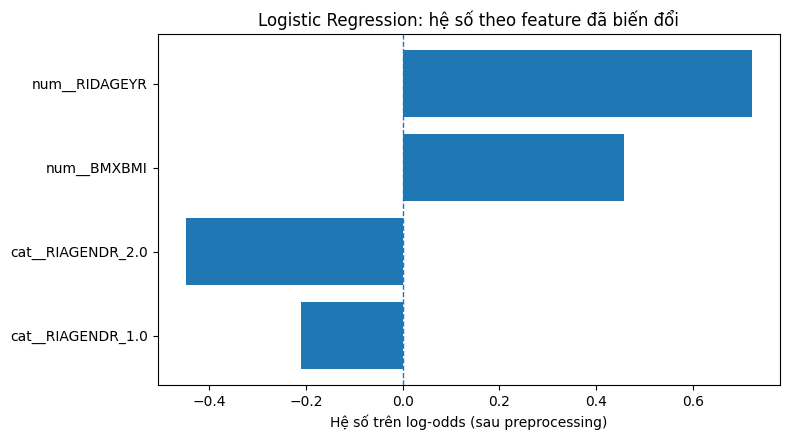

In [3]:
prep = pipe.named_steps["prep"]
clf = pipe.named_steps["model"]
encoded_names = prep.get_feature_names_out()
coefs = np.asarray(clf.coef_).reshape(-1)
assert len(coefs) == len(encoded_names)
coefficients = pd.DataFrame({
    "transformed_feature": encoded_names,
    "coefficient_log_odds": coefs,
    "odds_ratio_encoded_unit": np.exp(coefs),
})
coefficients["abs_coefficient"] = coefficients["coefficient_log_odds"].abs()
coefficients = coefficients.sort_values("abs_coefficient", ascending=False)
display(coefficients.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
order = coefficients.iloc[::-1]
ax.barh(order["transformed_feature"], order["coefficient_log_odds"])
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Hệ số trên log-odds (sau preprocessing)")
ax.set_title("Logistic Regression: hệ số theo feature đã biến đổi")
fig.tight_layout()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "07_coefficients.png", dpi=160)
plt.show()
coefficients.to_csv(OUTPUT_DIR / "07_coefficients.csv", index=False)


## 3. Permutation Importance trên Validation (không train)

Xáo mỗi feature gốc trong `X_val` rồi quan sát **giảm ROC-AUC**, lặp 20 lần để giảm nhiễu ngẫu nhiên. Ưu điểm: đánh giá trên **toàn pipeline**, không xáo riêng cột one-hot. Giá trị lớn nghĩa là mô hình hiện tại phụ thuộc hơn vào feature đó để giữ ROC-AUC trên **Validation**; không suy ra nguyên nhân gây bệnh. Có thể gặp giá trị âm do nhiễu và các biến tương quan.

**Không dùng kết quả này để thay đổi feature/model rồi đánh giá lại Test 6B.**


,feature,importance_mean_auc_drop,importance_std_auc_drop
0,RIDAGEYR,0.1570,0.0211
2,BMXBMI,0.0633,0.0139
1,RIAGENDR,-0.0063,0.0029


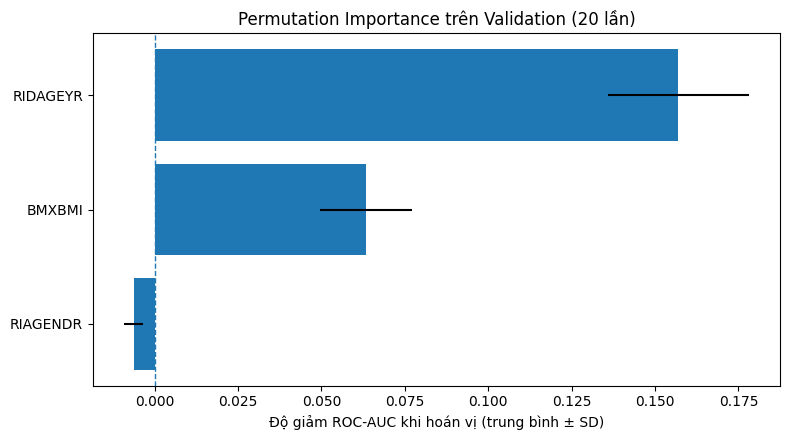

In [4]:
perm = permutation_importance(
    pipe, X_val, y_val,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=1
)
perm_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean_auc_drop": perm.importances_mean,
    "importance_std_auc_drop": perm.importances_std,
}).sort_values("importance_mean_auc_drop", ascending=False)
display(perm_df.round(4))
perm_df.to_csv(OUTPUT_DIR / "07_permutation_importance_validation.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
rev = perm_df.iloc[::-1]
ax.barh(rev["feature"], rev["importance_mean_auc_drop"], xerr=rev["importance_std_auc_drop"])
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Độ giảm ROC-AUC khi hoán vị (trung bình ± SD)")
ax.set_title("Permutation Importance trên Validation (20 lần)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_permutation_importance.png", dpi=160)
plt.show()


## 4. Local Explanation: phân rã log-odds trên 3 ví dụ Validation

Chọn ba ví dụ theo **điểm số thấp nhất, gần ngưỡng 0,225, cao nhất** trên Validation để mô tả cách Logistic Regression tính toán. Đây không phải SHAP; chỉ là phép phân rã tuyến tính **sau** preprocessing, tương ứng `logit = intercept + Σ(β_j × z_j)`. Nhãn dự đoán dùng ngưỡng đã khóa, không điều chỉnh. Không in `SEQN` hoặc dữ liệu nhận dạng.


In [5]:
indexes = [int(np.argmin(p_val)), int(np.argmin(abs(p_val - THRESHOLD_LOCKED))), int(np.argmax(p_val))]
unique_indexes = list(dict.fromkeys(indexes))
labels = ["lowest_score", "near_threshold", "highest_score"]
local_rows = []
example_summary = []
for label, idx in zip(labels, indexes):
    row_X = X_val.iloc[[idx]]
    transformed = prep.transform(row_X)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()
    z = np.asarray(transformed).ravel()
    contributions = z * coefs
    logit_reconstructed = float(clf.intercept_[0] + contributions.sum())
    reconstructed_p = float(expit(logit_reconstructed))
    actual_p = float(p_val[idx])
    assert abs(reconstructed_p - actual_p) < 1e-9, "Không khớp xác suất: kiểm tra pipeline."
    example_summary.append({
        "example_type": label,
        "predicted_score": round(actual_p, 5),
        "predicted_label_locked_0225": int(actual_p >= THRESHOLD_LOCKED),
        "observed_label": int(y_val.iloc[idx]),
    })
    local_rows.append({"example_type":label,"transformed_feature":"(intercept)","log_odds_contribution":float(clf.intercept_[0])})
    for name, c in zip(encoded_names, contributions):
        local_rows.append({"example_type":label,"transformed_feature":name,"log_odds_contribution":float(c)})

print("Ba ví dụ được chọn theo điểm số trên Validation (KHÔNG dùng Test, không in SEQN):")
display(pd.DataFrame(example_summary))
local_df = pd.DataFrame(local_rows)
display(local_df.round(4))
local_df.to_csv(OUTPUT_DIR / "07_local_contributions_examples.csv", index=False)


Ba ví dụ được chọn theo điểm số trên Validation (KHÔNG dùng Test, không in SEQN):


,example_type,predicted_score,predicted_label_locked_0225,observed_label
0,lowest_score,0.03941,0,0
1,near_threshold,0.22488,0,0
2,highest_score,0.80025,1,0


,example_type,transformed_feature,log_odds_contribution
0,lowest_score,(intercept),-0.6653
1,lowest_score,num__RIDAGEYR,-1.2808
2,lowest_score,num__BMXBMI,-0.7991
3,lowest_score,cat__RIAGENDR_1.0,-0.0000
4,lowest_score,cat__RIAGENDR_2.0,-0.4484
5,near_threshold,(intercept),-0.6653
6,near_threshold,num__RIDAGEYR,-1.1550
7,near_threshold,num__BMXBMI,1.0312
8,near_threshold,cat__RIAGENDR_1.0,-0.0000
9,near_threshold,cat__RIAGENDR_2.0,-0.4484


## 5. Xuất tổng hợp và gửi kết quả

Khi chạy xong, gửi lại **output cuối**, ảnh `07_coefficients.png`, `07_permutation_importance.png`, hoặc hai CSV. Tôi sẽ phân tích tác động của từng biến theo mô hình bạn đã fit và ghi vào `07-Model-Explainability.md`.

**Ghi nhớ:** Kết quả Test trước đó đã chốt, không đánh giá lại; Bước 7 không tạo model mới, không sửa threshold.


In [6]:
summary = {
    "experiment": "EXP-EXPLAIN-VAL-001",
    "step": "phase3_step7",
    "model": "LogisticRegression",
    "model_sha256": model_hash,
    "features": FEATURES,
    "validation_n": int(len(val)),
    "validation_positive_n": int(y_val.sum()),
    "validation_roc_auc_reproduced": float(auc),
    "threshold_locked_from_step6a": THRESHOLD_LOCKED,
    "coefficients": coefficients[["transformed_feature", "coefficient_log_odds", "odds_ratio_encoded_unit"]].to_dict(orient="records"),
    "permutation_auc_drop": perm_df.to_dict(orient="records"),
    "local_examples": example_summary,
    "test_opened_in_step7": False,
    "fit_executed": False,
    "model_modified": False,
    "limitations": ["research only; HbA1c >= 5.7% label", "not a causal explanation", "not survey weighted", "post-test interpretability; no new holdout evaluation"]
}
(OUTPUT_DIR / "07_explainability_summary.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
print("===== BƯỚC 7 — NHANES MODEL EXPLAINABILITY (NGƯỜI DÙNG CHẠY) =====")
print("Model:",summary["model"],"| SHA256:",model_hash)
print("Validation:",len(val),"| positive:",int(y_val.sum()),"| ROC-AUC:",round(auc,4))
print("---- COEFFICIENTS ----")
print(coefficients[["transformed_feature","coefficient_log_odds","odds_ratio_encoded_unit"]].round(4).to_string(index=False))
print("---- PERMUTATION IMPORTANCE (ROC-AUC DROP) ----")
print(perm_df.round(4).to_string(index=False))
print("---- LOCAL EXAMPLES ----")
print(pd.DataFrame(example_summary).to_string(index=False))
print("Saved:", OUTPUT_DIR)
print("FIT: NO | TEST OPENED IN STEP7: NO | MODEL MODIFIED: NO")
print("===== KẾT THÚC — GỬI KẾT QUẢ CHO TÔI =====")


===== BƯỚC 7 — NHANES MODEL EXPLAINABILITY (NGƯỜI DÙNG CHẠY) =====
Model: LogisticRegression | SHA256: 31e9c94b0f14369be7920b9315b026d0c4afedb9f7b2885d120d631d930582b1
Validation: 705 | positive: 208 | ROC-AUC: 0.7173
---- COEFFICIENTS ----
transformed_feature  coefficient_log_odds  odds_ratio_encoded_unit
      num__RIDAGEYR                0.7215                   2.0575
        num__BMXBMI                0.4583                   1.5813
  cat__RIAGENDR_2.0               -0.4484                   0.6387
  cat__RIAGENDR_1.0               -0.2102                   0.8104
---- PERMUTATION IMPORTANCE (ROC-AUC DROP) ----
 feature  importance_mean_auc_drop  importance_std_auc_drop
RIDAGEYR                    0.1570                   0.0211
  BMXBMI                    0.0633                   0.0139
RIAGENDR                   -0.0063                   0.0029
---- LOCAL EXAMPLES ----
  example_type  predicted_score  predicted_label_locked_0225  observed_label
  lowest_score          0.03941   